# 사전과제 : 딥러닝 1 focus on image + sequence

# 1. 합성곱 신경망 : CNN

## 1-(0). 픽셀과 채널
### 1. 픽셀이란?
- **픽셀** : 이미지 데이터를 구성하는 가장 기본적 단위
- 하나의 픽셀 = 이미지 특정 위치의 색상이나 밝기 정보를 갖고 있다. <br>
1. 이미지 데이터에서의 활용
    - 이미지 크기 = 세로 픽셀 수 * 가로 픽셀 수 (흑백일 경우) 
2. 픽셀 값의 표현 방법
    - **픽셀 값** : 이미지의 색상, 밝기를 *숫자*로 표현한 값
    - 흑백 이미지 -> 하나의 픽셀 값으로 밝기 표현 (0 : 검정 ~ 255: 흰색 )
    - 컬러 이미지 -> R G B (0~255, 세 값의 조합으로 하나의 색이 만들어진다.)

### 2. 채널이란?
- **채널** : 이미지의 색상 정보를 구성하는 각각의 데이터 층. <br> = 하나의 이미지에서 색상, 밝기 정보를 구분해서 저장하는 단위

### 3. 색공간이란?
- **색공간** : 이미지를 구성하는 색상을 숫자로 표현하는 방법과 체계, 기준에 따라 다양한 색공간 존재
     - 그레이 스케일 : 색상 없이 밝기 정보 만으로 <br>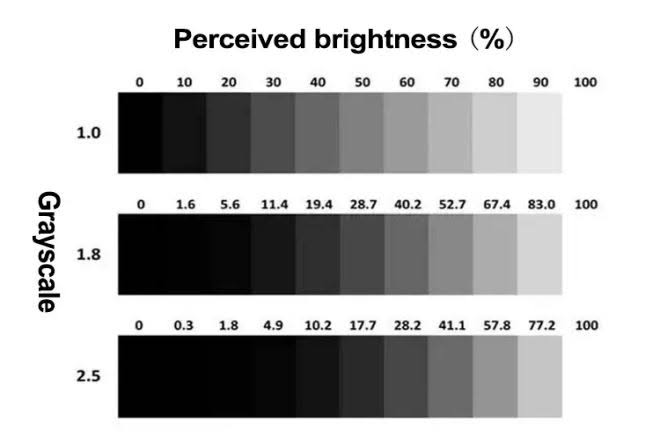<br>
         - 각 픽셀 = 하나의 채널 값 (0~255)
         - 채널 값이 1인 이유 -> 밝기 정보만 저장해도 되기 때문 (하나의 값만 표현) <br> <-> RGB (3가지 채널)
         - 저장 방법 : 3차원 텐서로 표현 (28x28x1)
             - 텐서 : 데이터가 몇 개의 축을 가지느냐가 차원을 결정 
             - 0차원 = 스칼라, 1차원 = 벡터, 2차원 = 행렬, 3차원 이상 = 행렬이 여러 개 또는 채널 배치 등의 추가 축이 포함된 다차원 구조
     - RGB : 빨강 초록 파랑의 조합으로 색 표현 <br> 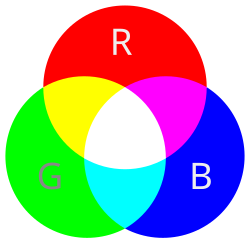 <br> 
          - 각 픽셀 = 삼원색의 조합
          - 채널 값 = 3
          - 저장 방법 : 높이가 28, 너비가 28 인 이미지 = (28 x 28 x 3) -> 3차원 텐서
     - HSV : 색상 채도 명도 기준으로 색 표현 <br> 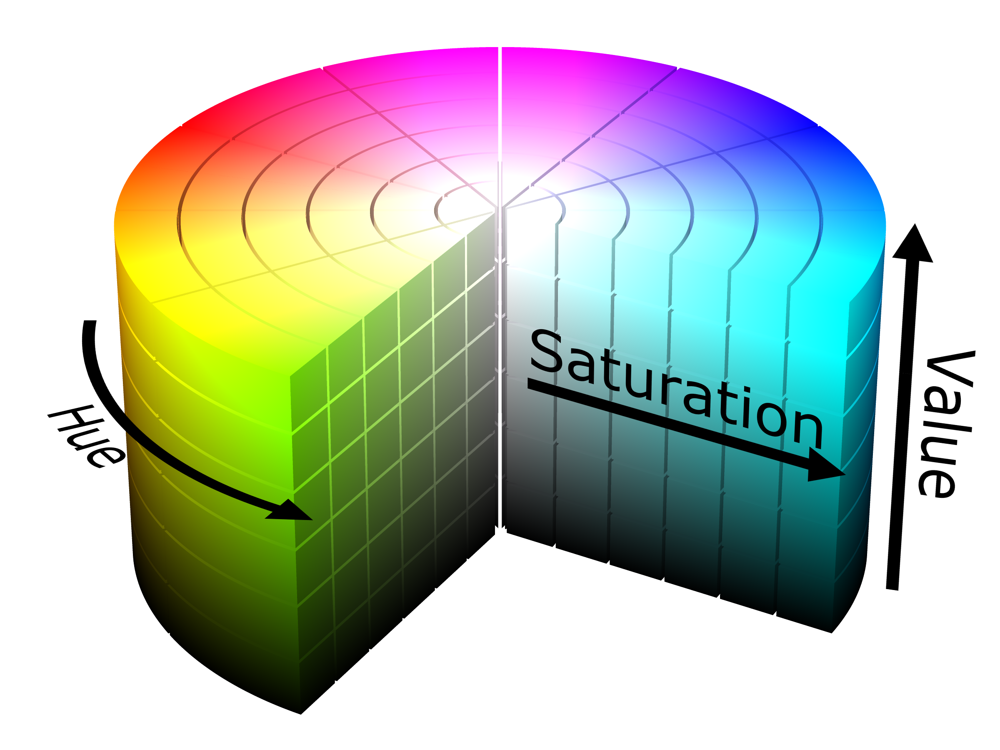


## 1- (1) CNN의 개념
### 1. 이미지 인식 방법의 차이
1. 사람이 이미지 인식하는 방법
- 물체를 구분하는 데에 중요한 영역과 특징에 더 집중한다.
- 이미지에 어떤 물체가 있는지 판단하고 관계까지도 파악
2. 컴퓨터가 이미지를 인식하는 방법
- 이미지를 픽셀 단위를 구분하고 픽셀에 저장된 숫자 정보를 처리한다. 
- 이미지 = 숫자 데이터
3. 픽셀 정보를 **그냥** 학습할 때의 문제점
- 이미지를 단순히 1차원 배열로 펼쳐서 학습하면 원래의 2차원 공간 구조가 잘 활용되지 못한다. 
     - 픽셀들의 관계가 모델에 직접적으로 반영이 되지 않기 때문
     - -> 이로 인해 눈, 귀, 꼬리처럼 주변 픽셀들이 모여 만들어지는 이미지 특징을 학습하기가 어려워진다

### 2. MLP와 CNN의 구조 비교
- MLP = FC layer +....+ FC layer <br> 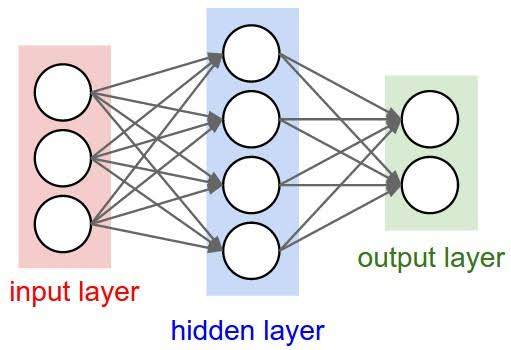 <br>
     - 입력된 데이터를 FC layer에 전달하여 학습하는 구조이다.
     - 일반적으로 2차원 이미지를 1차원으로 펼친 후 사용

- CNN **(Conv+Pool) + Flatten** + FC layer +....+ FC layer <br>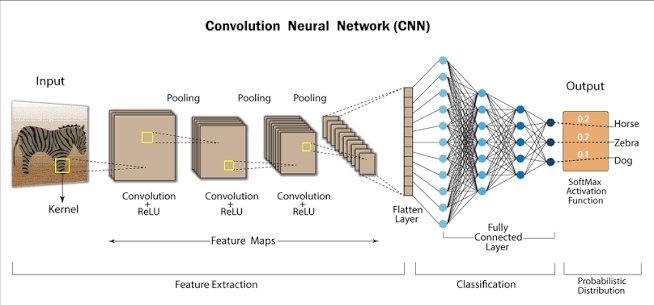 <br>
     - 이미지의 공간적 특징을 유지하면서 Conv 와 Pool을 반복해서 이미지 특징을 추출
     - 이후 Flatten을 통해 1차원으로 변환 후 FC layer로 이미지를 분류
- **큰 차이점은 CNN이 FC 레이어를 사용하기 전 Conv와 Pool을 이용해서 이미지의 특징을 학습하는 과정이 추가**

### 3. CNN
크게 학습 부분 + 분류 부분  <br>
-> 분류는 회귀/분류모델과 유사 / CNN의 추가 핵심 과정은 **학습부분**
- 특징 추출
     - convolution layer : 필터 (kernal) 를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출한다.
     - pooling layer : 추출된 특징 맵의 크기를 줄이고, 주요 특징을 유지해서 연산량을 감소시킴
     - 특징 추출 과정을 반복
- Flatten
     - 여러 차원으로 이루어진 특징 맵을 FC layer에 입력하도록 1차원으로 변환
- 분류
     - fully connected layer : 추출된 특징들을 종합해서 이미지가 어떤 클래스에 속하는지 *최종적으로 분류*


## 1-(2) 왜 이미지 처리에 MLP가 아닌 CNN을 사용할까

### 1. 이미지 데이터의 구조
1. 흑백 이미지의 구조
- 흑백 이미지 = 각 픽셀에 하나의 밝기 (0~255 : 0이 검정, 255가 흰색)
- H(세로픽셀 수, 이미지 높이) x W(가로픽셀 수, 이미지의 너비) 형태의 2차원 배열로 표현 
2. 컬러 이미지의 구조
- RGB 이미지는 하나의 픽셀을 빨강, 초록, 파랑 세가지 색상으로 구성 (한 채널 :0~255, 세 값의 조합으로 하나의 색상 만들어진다.)
- H x W x 3 형태의 3차원 배열로 표현
3. 대표적인 이미지 데이터셋
- 손글씨 숫자 이미지로 구성된 MNIST <br>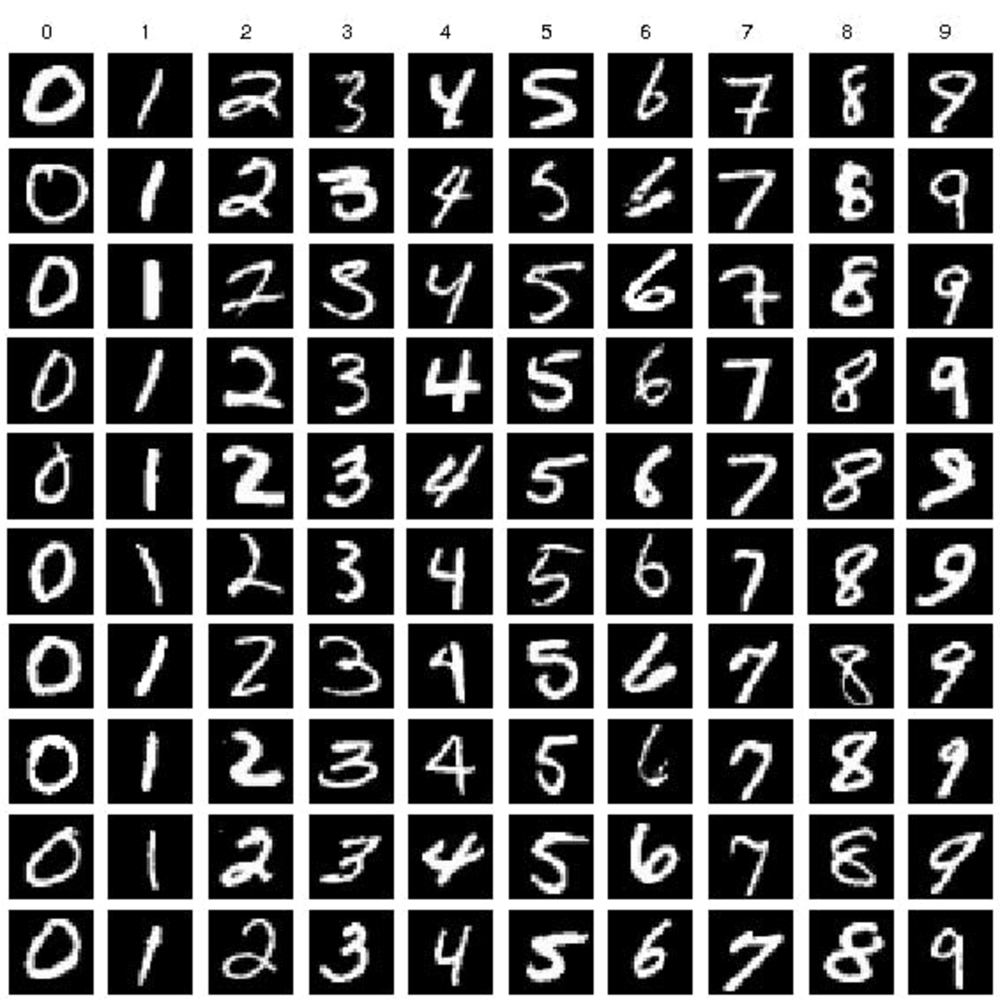 <br> 0부터 9까지의 숫자를 담은 크기의 흑백 이미지 데이터셋
4. 이미지 구조를 유지하는 모델이 필요한 이유
- 이미지는 주변 픽셀 간 관계와 위치 정보가 중요함
- -> 따라서 픽셀 간 공간적 관계와 이미지 구조를 유지하면서 특징을 학습할 수 있는 모델이 필요하다.

### 2. MLP의 한계
1. 위치 크기 회전 등 변화에 취약
- 1차원 배열에서 입력받고, 각 위치에 대응하는 가중치 학습하기에 이미지가 조금만 이동해도 기존 값에 있던 픽셀에는 0이 들어가고 새로운 위치에 픽셀 값이 들어가는 오류 (입력 데이터가 달라지는) 가 발생한다.
     - = 학습 데이터에서 보지 못한 위치, 형태 변화가 발생하면 기존의 형태와 다르게 인식할 가능성이 높아진다.
- **CNN에서는** ... **이미지 안에 해당 특징이 존재하는지를 학습**한다. 
     - convolution : 이미지의 특정한 특징을 추출해서 어느 위치에 나타나도 동일한 필터로 감지
     - pooling : 특징 맵의 크기를 줄이는 과정을 통해 작은 위치 변화에도 특징 유지를 도움.

2. 파라미터 폭팔
- MLP에서 완전연결 구조로 인해 파라미터 급증이 이루어진다. 
     - 완전 연결 구조 : 이전 레이어의 모든 노드가 다음 레이어의 모든 노드와 빠짐없이 연결되어 있는 구조 <br>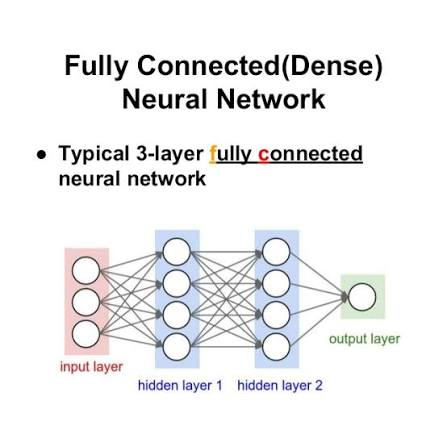 <br>
     - 입력 데이터가 다음 층 모든 뉴런에 영향
     - 데이터 간 복잡 & 비선형적 관계 학습에 유리
     - 이미지를 1차원으로 입력하기에 이미지의 공간적 정보가 사라지고 파라미터가 급증하게 됨.
- 가중치 수 = 이미지 픽셀의 개수
- 과적합 가능성 상승, 이미지가 클수록 학습이 느림

- **CNN에서는** ... **이미지가 커지더라도 필터의 크기와 개수가 동일하면 파라미터 수는 크게 증가하지 않는다.**
     - CNN은 부분 연결 구조를 사용한다. 
     - 동일한 필터의 가중치를 여러 위치에서 공유 -> 위치마다 새롭게 가중치를 만들지 않아도 된다.

3. 공간 정보 손실 
- MLP에서는 2차원,3차원 이미지 데이터 -> 1차원 벡터 로 만드는 Flatten 과정을 거친다. 
     - 픽셀 숫자 값 자체가 사라지진 않지만, 2차원 공간 구조가 명시적으로 유지되지 못해 *픽셀 간 위치 관계나 주변 픽셀들로 만들어진 특징을 직접적으로 활용하기 어렵다는 한계* 가 존재

- **CNN에서는** ... **이미지의 공간적 특징을 먼저 학습한 후 Flatten을 진행** -> *픽셀의 위치 관계와 주변 영역 특징을 잘 활용할 수 있다.*
     - 이미지를 입력받자마자 1차원으로 펼치지 않고 다차원 구조를 유지한채로 처리한다. 
     - convolution layer : 이미지의 작은 영역을 대상으로 연산 -> 주변 픽셀 간 관계와 위치 정보 활용
     - pooling layer : 공간적 구조를 어느정도 유지하면서 크기 줄임 
     - 여러 개층을 거치고 나서 flatten진행



## 1 - (3). 합성곱과 풀링
1. Convolution layer
- 개념 : 입력 이미지 전체를 일정한 크기의 필터로 훑으면서 이미지 특징을 추출하고 학습 = 입력 데이터에 필터 적용해서 연산 수행하고 데이터 만들어냄
     - 필터 : 이미지의 특정 패턴이나 특징 감지 (수직선, 수평선, 모서리, 질감 등등 ) <br> 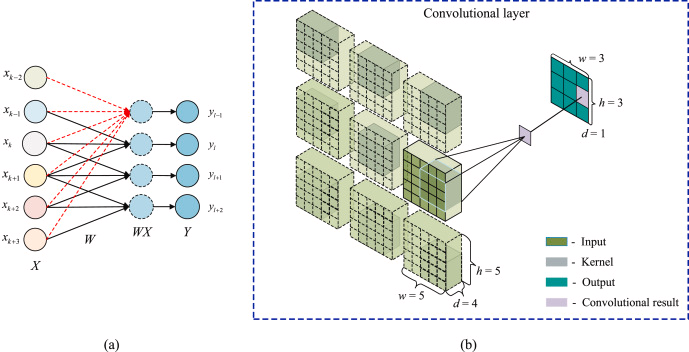 <br>
- 연산 과정 <br> 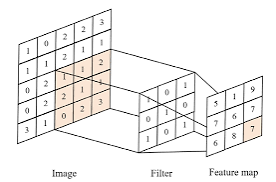<br> 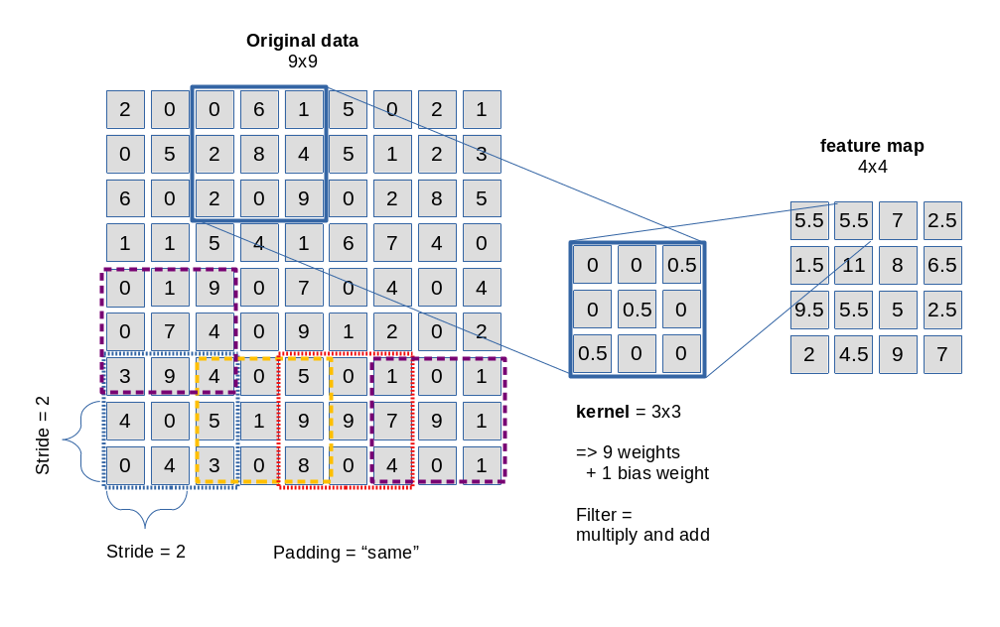
     - 1. 필터가 이미지 위를 슬라이딩 
          - 작은 크기의 필터를 입력 이미지 왼쪽 위에 배치
          - 이후에 정해진 간격만큼 오른쪽으로 이동하면서 이미지의 각 영역을 확인하고 한 행 연상 끝나면 다음 행으로 이동
     - 2. 각 위치에서 요소별 곱셈 후 합계 계산
          - 필터가 위치한 영역의 픽셀 값과 필터의 가중치를 각각 같은 위치까지 곱한다 
          - 곱하고 모두 더해서 하나의 숫자를 계산
     - 3. feature map에 저장
          - 한 위치에서 계산된 결과값을 feature map의 해당 위치에 저장
          - 필터가 모든 위치에서 연산을 마치면 하나의 map 완성
- 커널과 필터의 차이
     - 커널 : 이미지의 특정 패턴을 추출하기 위해 사용하는 2차원 가중치 행렬
     - 필터 : 여러 개의 커널이 모인 집합
     - 예시 : 컬러 이미지는 3가지 채널 -> 각 채널 별로 연산 수행할 3개의 커널이 필요 , 그 3개의 커널 = 필터 -> 3개의 커널을 연산한 뒤 결과를 모두 더해 최종적으로 하나의 채널을 만들어낸다. (feature map)

- feature map
     - convolution 연산을 통해 생성되는 결과 데이터
     - 필터가 특정 특징에 반응할수록 해당 위치의 feature map 값이 커진다.
     - feature map 개수 = 필터의 개수
     - 예시 : RGB이미지에 3x5x5 크기의 필터 하나 적용 시 맵 하나 형성 =  ( 입력 채널 수 3 ) x (필터의 공간적 크기 5x5)

- 정리 : CNN은 여러 개의 필터로 이미지의 다양한 특징을 추출하고 여러 개의 feature map을 생성해서 이미지에 포함된 정보들을 학습한다.

2. padding
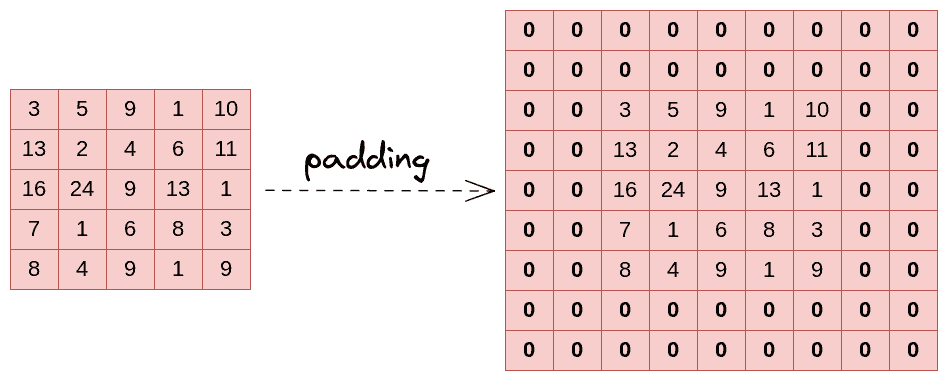 <br>
- 개념 : concolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 방법이다. (일반적으로 0을 추가하는 zero padding 방식을 많이 사용)
- 효과 : <br>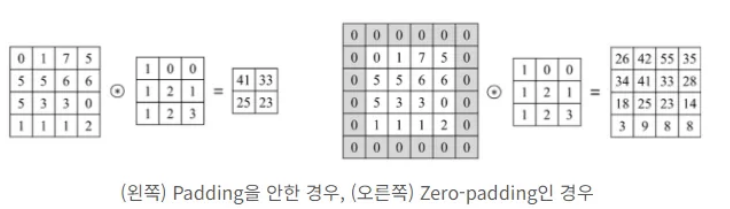 <br> 
      - padding은 가장자리 영역이 필터가 적용되는 횟수가 적어지게되는 문자를 보완하며 feature map의 크기를 조절하는 역할을 한다. (이미지의 크기가 작아지는 것을 방지
      - 이미지의 가장자리도 연산에 충분히 포함되도록 한다.

3. stride (보폭)
- **특징을 얼마나 세밀하게 추출할지, 연산 효율을 어떻게 조절할지** 결정하는 요소<br>
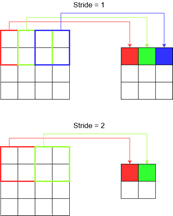 <br>
- stride 1 : 한 칸씩 이동, 이미지의 여러 위치 세밀하게 확인, feature map 상대적으로 큼 -> 필터가 많은 위치 확인해서 *세부족 특징 추출에 유리*

- stride 2 : 두 칸씩 이동, 일부 위치를 건너뛰며 연산 , feature map 상대적으로 작음. -> 필터가 이동하는 횟수가 줄어서 *연산량을 줄이고 feature map의 크기 축소*

- stride가 커질수록 필터가 한 번에 이동하는 거리가 늘어나기에 입력 이미지에서 연산하는 위치가 줄어든다. -> feature map 크기가 작아지고, 처리해야하는 데이터의 양도 감소 

4. pooling
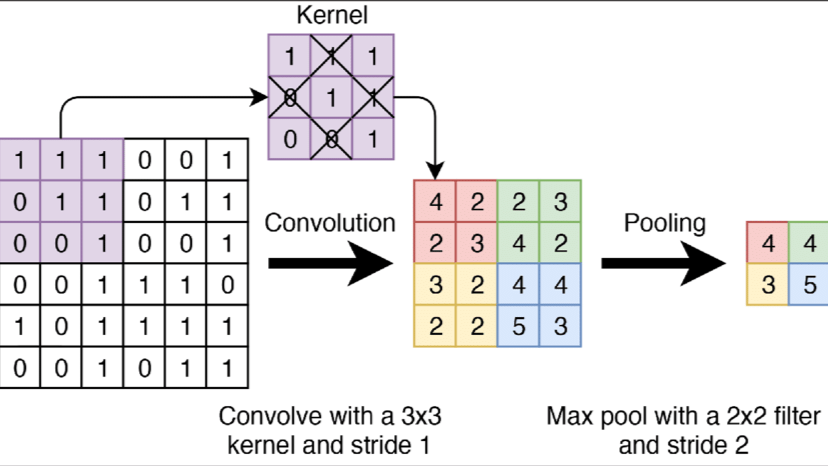 <br>
- 개념 : 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식할 수 있도록 한다.
     - 일정한 크기의 영역 설정, 해당 영역의 값을 하나로 요약 (일반적으로 2x2 크기, 각 영역의 최댓값과 평균값 계산)
     - 이미지의 공간적 크기를 축소해서 처리해야하는 데이터 양을 줄임
- pooling을 사용하지 않는다면 
     - 엄격하게 특정한 픽셀 위치에서만 패턴을 찾으려고 한다. 따라서 조금만 요소가 이동하면 동일 특징으로 인식하지 못한다.

- 종류 <br>
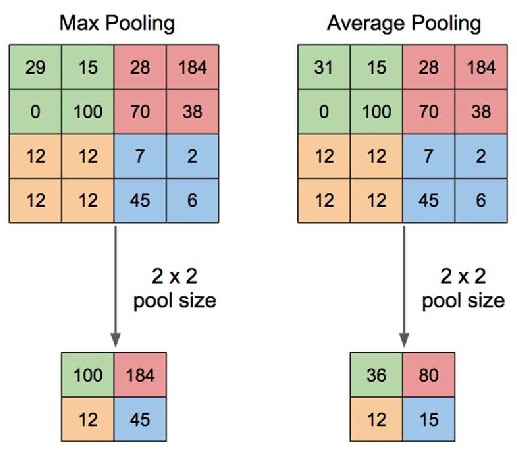 <br>
     - max : 지정된 영역 내에서 가장 큰 값 선택
     - average : 지정된 영역 내에서 모든 값의 평균 계산

- 장단점
     - 장점
        * 차원 축소로 계산량이 감소
        * 위치 변화에 대한 강건성 (작은 변화에도 비슷한 특징 유지)
        * 과적합 방지에 도움 (불필요한 세부 정보와 공간적 복잡성을 줄임)
        * 노이즈 영향 완화 
     - 단점
        * 정보 소실의 위험
        * 정확한 위치 정보의 감소

### CNN 구조의 정리 
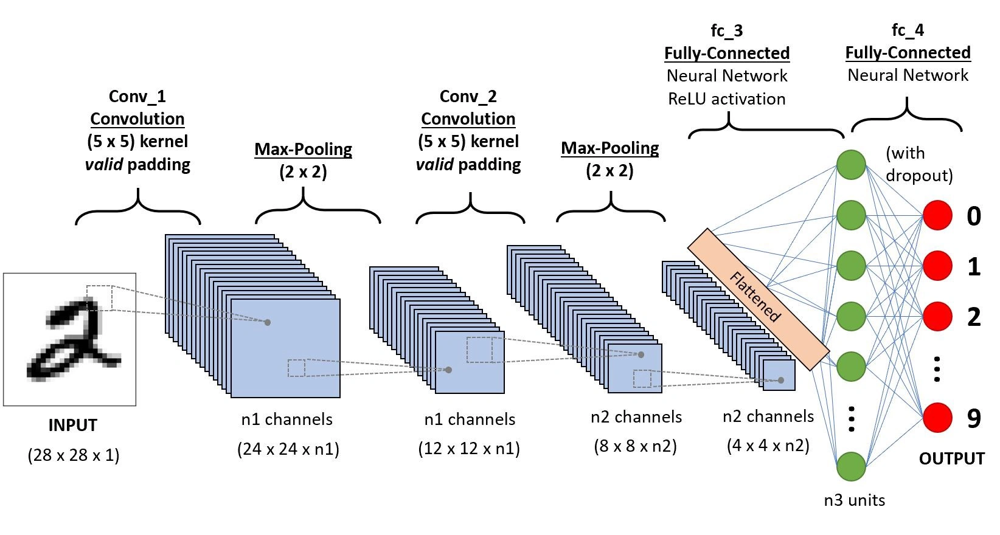 <br>

input -><br> convolution layer (필터로 이미지 특징 추출) ; padding (가장자리 출력 크기 조절) + stride (이동 간격 조정) -> <br>pooling layer (주요 특징 유지 및 차원 축소) ; convolution & pooling 반복 -> <br>flatten (다차원->1차원) -> <br>fully connected layer (추출된 특징으로 이미지 분류) -> <br>output

## 1 - (4) 대표적 CNN 아키텍처 살펴보기
1. Alexnet <br> 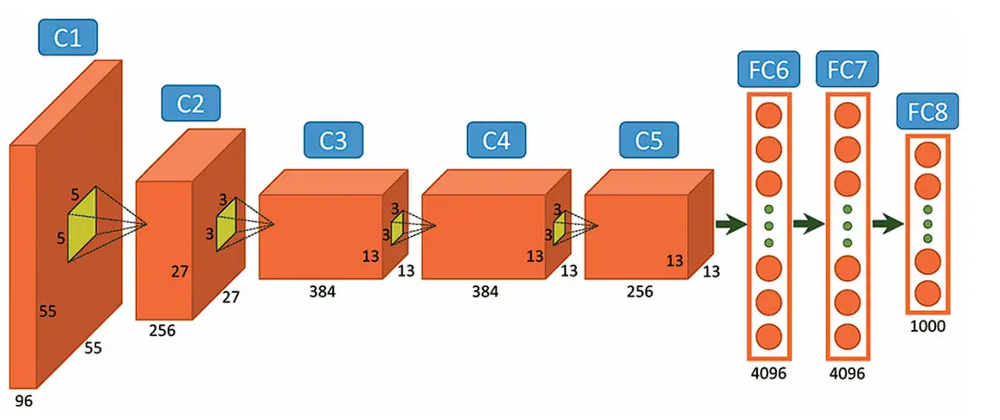 <br>
 - 총 8개의 학습 계측 ( convolution 5, fully connected 3)
 - 특징
      * ReLu 함수 도입
      * 다중 GPU 병렬 연산 
      * 드롭아웃 : 과적합을 막기 위해
      * 데이터 증강 : 인위적으로 훈련 데이터 대폭 증가
      * 로컬 응답 정규화 : 강하게 활성화된 뉴런 주변을 감쇠

2. VCGNet <br>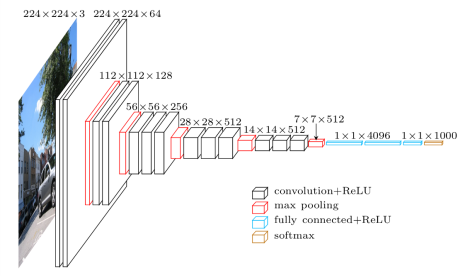 <br>
  - 총 16개의 학습 계층 ( convolution 13, fully connected 3)
  - 특징
      * 작은 필터의 반복적 사용 : 다양한 특징 학습
      * 깊은 네트워크 : 복잡하고 추상적 이미지 특징 학습
      * 일관된 구조 : 구조가 비교적 단순하고 이해하기 쉬움
  - Alexnet에 비해서 더 복잡한 형태까지 세밀하게 학습 가능
   
3. ResNet <br> 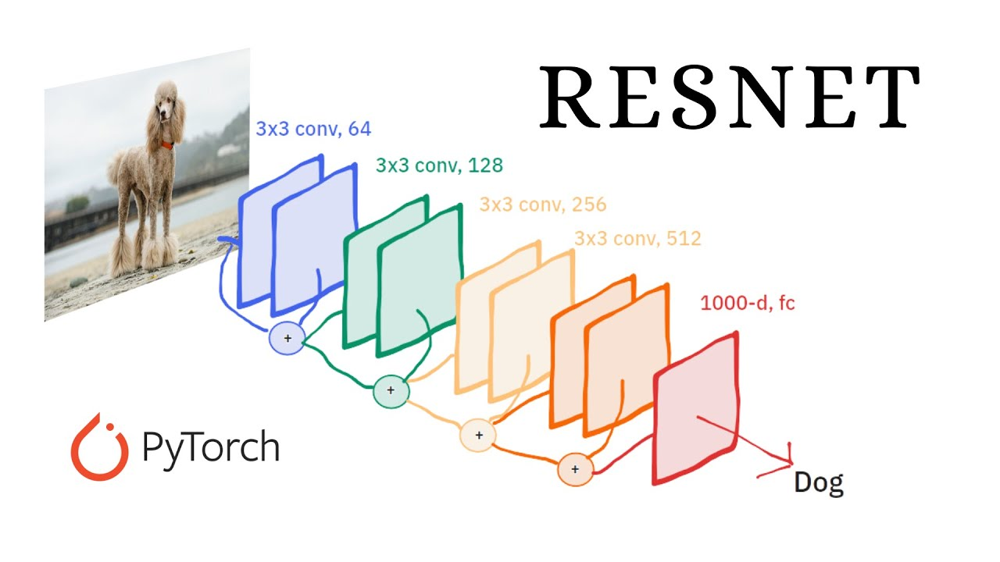 <br>
- 구조 :  convolution 사이에 skip connection 을 추가한 구조
      * skip connection : 입력정보를 뒤쪽 계층으로 직접 전달하는 연결 방식
      * 기존 계층 통과한 결과 + 처음 입력된 정보 -> 다음 계층

# 2. 이미지 딥러닝 응용
## 2-(1) 이미지 분류
- 이미지 분류 모델 : 이미지를 수치 데이터 (픽셀값) 으로 인식 -> 사전에 정의된 클래스 중 하나로 분류
- 모델 : Alexnet, VGG, ResNet, VIT 
     - VIT : 이미지를 작은 패치로 나누고, 트랜스포머에 입력하여 이미지 특징을 학습하는 모델, 필터를 반복적으로 적용하는 CNN과 다르게 Attention 활용해서 이미지 패치 간의 관계를 학습 <br> 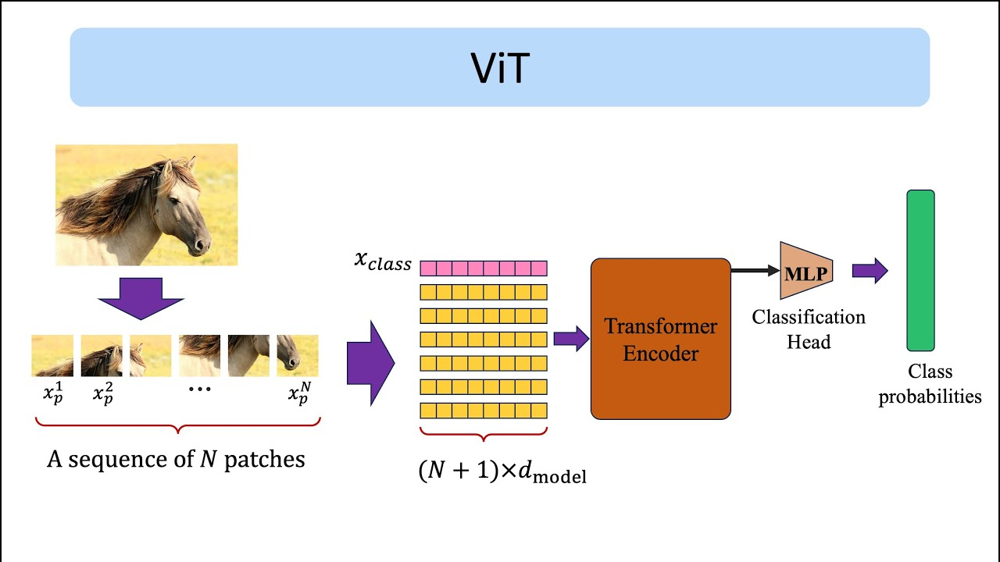

- CNN의 확장 가능성 
     - 클래스로 분류하는 작업뿐이 아니라, *이미지 내에 존재하는 여러 객체를 찾아내는 작업에도 활용*
     - YOLO 모델 : 이미지 내의 사람,자동차,자전가 등을 각각 탐지하고 객체의 종류와 위치를 동시에 예측. <br>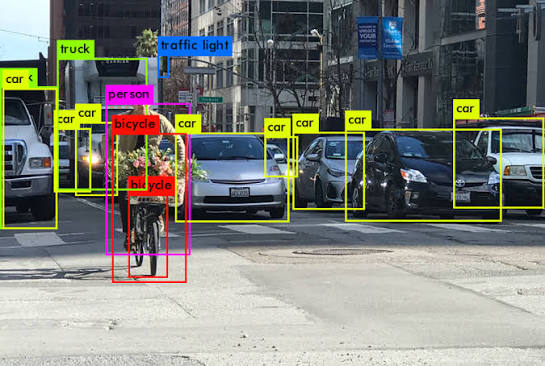

## 2-(2) 객체 탐지
- 객체 탐지 : 이미지 내의 개별 객체의 종류와 위치를 함께 예측 <br>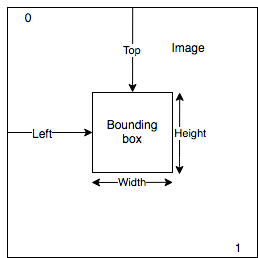 <br>
     - bounding box : 이미지에서 객체가 위치한 영역을 둘러싸는 사각형
     - 객체 탐지 모델은 사각형의 위치와 크기를 예측해서 이미지 안에서 객체가 어디에 있는지 표시
     - 중심 좌표 (x,y), 너비 (w), 높이 (h)
- 모델 적용 방식 : CNN으로 feature map을 얻고 그 위에 두 개의 head를 올리는 구조 
     - classification head : 객체의 종류 예측
     - regression head : 객체의 위치 좌표를 예측

## 2-(3) 이미지 캡셔닝
- 이미지 캡셔닝 : 이미지의 내용을 자연어 문장으로 표현하는 작업 (CNN+RNN) <br> 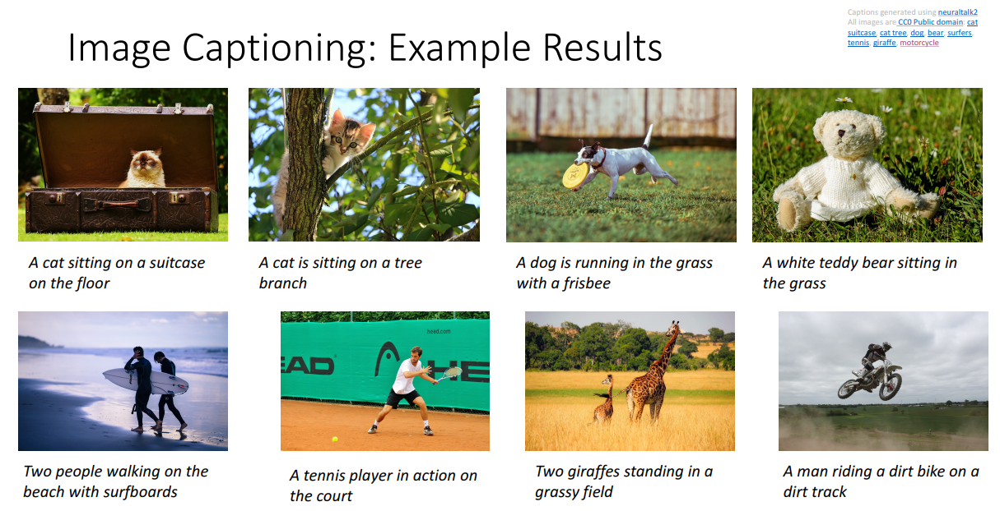<br>
- 모델 적용 방식 
     - CNN : 이미지 특징 추출
     - RNN : 문장 생성 
          * CNN이 추출한 이미지 특징을 바탕으로 단어를 순서대로 생성
          * 이전에 생성한 단어 정보를 활용해서 다음에 올 단어를 예측하고 하나의 문장 완성
- 이미지 캡셔닝 단계
     - 1. CNN을 이용한 특징 추출
     - 2. Attention Network를 이용해서 단어 생성
          * Attention은 문장을 생성할 때 단어와 관련된 중요한 영역에 더 높은 가중치를 부여하는 방식이다. 
    - 3. RNN을 이용해서 문장을 완성한다.

# 3. 과거를 기억하는 신경망 RNN

## 3- (1) 순차 데이터
### 1. 순차데이터란 
- 데이터의 순서가 의미를 갖는 데이터, 순서가 바뀌면 정보가 달라진다.

### 2. 순차 데이터 세부 분류
- 순서 기준 : 1) 시간적 (주가, 기온) 2) 비시간적 (문장 내 단어, DNA 염기 서열)
- 자료형 : 1) 수치형 (값의 크기와 거리가 의미가 있다: 음성, 비디오) 2) 범주형 (값의 크기와 거리가 의미가 없다: 구매이력)
     * 음성 : 소리 -> 시간에 따라 계속 변하는 공기의 진동, 각 시점에서 측정된 진폭값을 정수나 실수 형태의 수치로 변화시킨다
     * 비디오 : 이미지를 빠르게 연속으로 넘긴 것 , 프레임 재생 순서가 섞이면 의미가 달라진다

### 3. 기존 정형 데이터 vs 순차 데이터
- 정형 데이터 : 순서 바뀌어도 의미가 변하지 않는다. 
- 순차 데이터 : 순서에 의존한다 (문장 : 개가 사람을 물었다 != 사람이 개를 물었다)
- -> 순차 데이터를 처리할 별도의 모델이 RNN이다.

## 3-(2) RNN의 구조와 원리
### 1. 구조
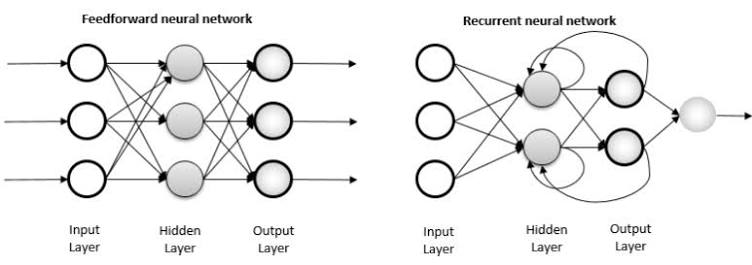 <br>
- 기존과 비교한 큰 차이점은 **은닉층의 순환 구조**
- 입력층 : 각 시점 t에 들어오는 입력 데이터 받는 곳
- 은닉층 : 현재 입력과 이전 시점의 은닉 상태를 함께 받아 새로운 은닉 상태를 만드는 곳
- 출력층 : 은닉 상태를 바탕으로 시점 t의 결과를 내보내는 곳
- 입력 가중치 : 입력 데이터 -> 은닉층 으로 보낼 때 붙는 가중치
- 순환 가중치 : 이전 은닉 상태 -> 현재 은닉층 으로 보낼 때 붙는 가중치
- 출력 가중치 : 은닉 상태 -> 출력 으로 바꿀 때 붙는 가중치

### 2. 원리
- 매 시점마다 *현재 시점 입력값*과 *이전 시점 은닉 상태*를 이용해서 현재의 은닉 상태를 계산하고 그 결과를 *다음 시점*으로 넘겨준다.
- **은닉 상태 계산** : 현재 입력 + 이전 은닉 상태 -> 새로운 은닉 상태
- **출력 계산** : 은닉 상태로 현재 시점의 출력을 만든다. 
     * 이진 분류면 시그모이드, 다중분류면 소프트맥스

### 3. RNN 아키텍쳐
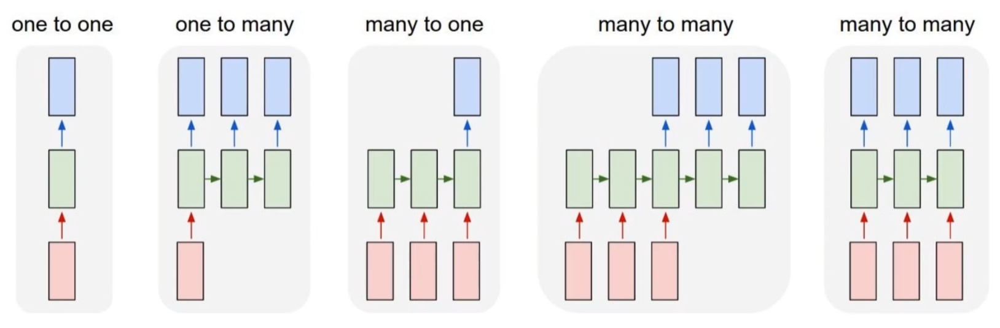 <br>
- one to many : 하나의 입력에서 시퀀스 출력
     * 시퀀스 : 순서가 있는 데이터의 나열
     * 이미지 캡셔닝에 사용된다. 
- many to one : 시퀀스 입력에서 하나의 값 출력
     * 스팸메일 분류
     * 감성 분류 (이진 : 긍/부정, 다중 : 기쁜/분노/슬픔...)
     * 전체 문장을 읽고 최종판별하기에 해당 구조 사용
- many to many : 시퀀스 입력에서 시퀀스 출력
     * 동기식 : 매 시점마다 즉각 출력
     * 비동기식 : 전체 입력을 다 읽은 후 한번에

## 3-(3) RNN 한계 및 장기 의존성 문제
### 1. 한계점 
- 시간에 따른 역전파 구조 : 순전파로 시퀀스를 처리하고 거슬러 올라가면서 오차를 전파하여 가중치의 기울기를 누적 계산한다.
     * 가중치 기울기 계산 : chain rule에 의해 한 시점을 거슬러 올라갈 때마다 활성화 함수 미분값 x 순환 가중치가 곱해진다.
          * chain rule : 여러 단계를 거쳐 연결되는 관계에서 각 단계의 변화율을 곱하면 전체 변화율이 되는 규칙
          * RNN에서의 chain rule : 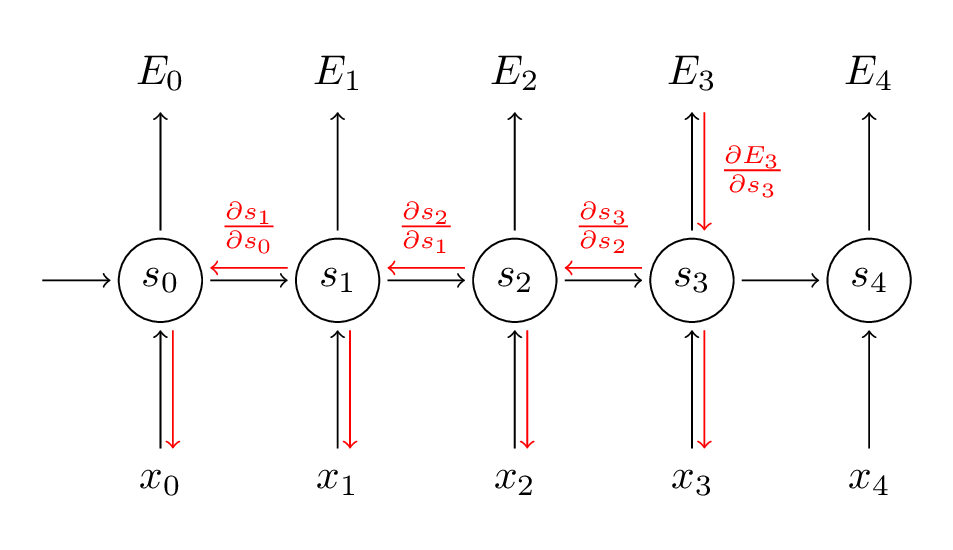 
- 기울기 소실 : 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작아져서 0에 가까워지는 현상이다. = 가까운 시점은 학습되지만 먼 과거 시점은 학습에 거의 반영되지 않게 된다.

- 기울기 폭주 : 역전파 과정에서 기울기가 과거로 갈수록 점점 커져 매우 큰 값이 되는 현상
     * 가중치가 크게 튀면서 오차가 갑자기 치솟거나 진동한다
          * 진동: 오차가 올라갔다 내려갔다를 반복하는 것
     * 오차값이 너무 커지게 되면 NaN이 발생하고 학습이 중단될 수 있다.
     * 긴 시퀀스일수록 학습이 불안정해진다.

- 느린 훈련 시간 : 하나씩 순서대로만 계산할 수 있어서 시퀀스가 길수록 학습 시간이 오래 걸리게 된다. + 메모리 부담도 커진다.
     *  CNN : 필터가 각 위치를 독립적으로 계산한다.
     *  RNN : 앞 시점 결과가 있어야 다음 계산 가능

### 2. 장기 의존성 문제
- 앞 세 가지 한계의 공통점 = 장기 의존성 문제 : 시퀀스에서 관련된 정보가 떨어져 있을 수록 RNN이 학습하지 못하는 문제



# 4. LSTM & GRU 똑똑하게 잊는 방법

## 4-(1) LSTM & GRU
- 장기 의존성 문제에 필요한 것 : 중요한 정보는 오래 기억하고 불필요한 정보는 잊는 메모리 구조 -> 아 아이디어를 구현한 대표 모델이 **LSTM & GRU** 이다.
- LSTM : 기억을 두 개의 상태로 나눠서 관리한다.
     * 셀 상태(장기기억) + 은닉 상태 (단기 기억&출력)
     * 세 개의 게이트 
          * forget gate : 장기 기억에서 필요 없는 내용 삭제
          * input gate : 새로 들어온 정보 중 중요한 것만 장기기억으로
          * output gate : 장기기억 중에 필요한 부분만 꺼내서 단기기억으로 보냄
     * 장기기억과 단기기억 분리 -> 정보를 정교하게 다룸
     * 그렇지만 구조가 복잡하고 계산이 많다.
- GPU : 기억을 하나로 통합해서 관리한다.
     * 하나로 통합된 상태 = 셀 상태와 은닉 상태로 나누지 않고, 은닉상태 하나로만
     * 두 개의 게이트
          * update gate : 과거 기억 : 새 정보 = 비율?
          * reset gate : 과거 기억을 얼마나 무시할 것인지
    * LSTM보다는 구조 단순, 하지만 정교함은 상대적으로 떨어진다.

## 4-(2) 게이트로 정보의 흐름 제어 : LSTM
### 1. 구조
- 핵심 : 셀 상태 = 구조도 맨 위를 가로지르는 선이 시점을 따라 쭉 이어진다.
     * 정보가 큰 변화 없이 다음 시점으로
     * 기억할 내용과 잊어버릴 내용을 선택해서 주요 정보를 오래 가져갈 수 있음
     * RNN은 매 시점을 통째로 덮어쓰지만 LSTM은 게이트로 *선택적으로 지우고 더한다*

### 2. 단계별로 알아보는 LSTM 수식
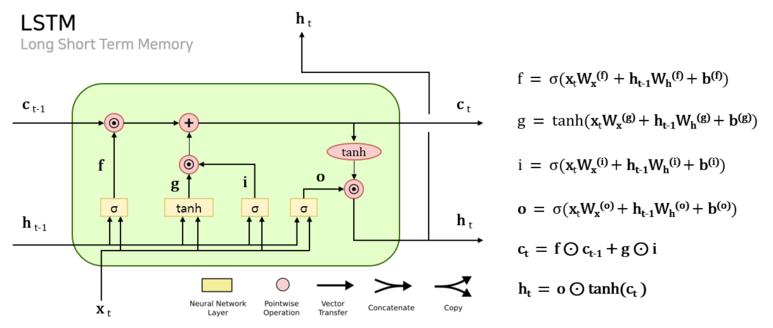
- 스텝 1 : forget gate 무엇을 잊을까
- 스텝 2 : input gate 무엇을 새로 기억할까
- 스텝 3 : final memory cell 기억 업데이트
- 스텝 4 : output gate : 무엇을 내보낼까

### 3. 장단점
- 장점:
     * 기울기 소실 완화 
     * 장기 의존성 학습 가능 ( 불필요한 정보 지움)
     * 시퀀스 과제에서 RNN보다 좋은 성능
- 단점 :
     * 계산량이 많아 학습이 느리고 메모리도 많이 사용
     * 여전히 시점을 순서대로 계산 -> 병렬 처리 불가
     * 기울기 소실을 완화한 것이지 없앤 것은 아니다 -> 매우 긴 시퀀스에는 여전히 한계이다.

## 4-(3) GRU 더 단순하고 효율적인 구조
### 1. 정의
- LSTM의 핵심 아이디어 (게이트로 정보를 선택적으로 기억 삭제)는 유지하면서 구조를 단순하게 줄인 모델 -> LSTM을 더 가볍게 만든 버전이다.

### 2. LSTM과의 차이점
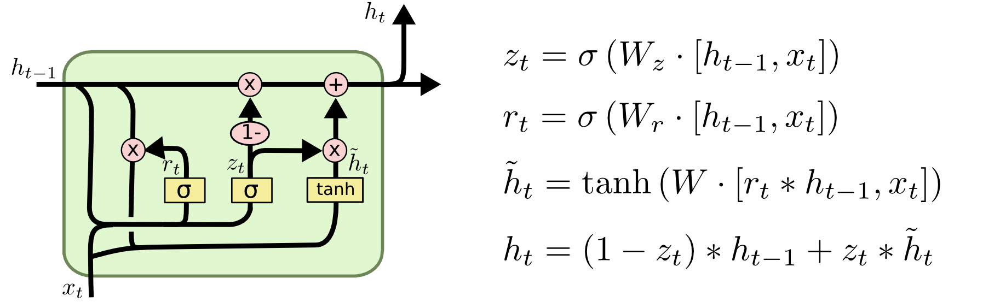 <br>
1. forget gate 와 input gate를 update gate 하나로 통합
2. reset gate 사용
3. output gate가 없음
4. gate의 개수가 3개 -> 2개로 감소 
     * 계산량이 줄어 학습 시간이 짧아진다.
     * 성능은 LSTM과 비슷하지만 과제에 따라 더 좋을 때도 있다.

### 3. 장단점 (LSTM대비)
- 장단점:
     * 구조 : 이해 구현이 쉬우나 장기 기억과 출력을 분리하지 못한다.
     * 속도 : 파라미터가 적어서 학습이 빠르고 메모리 사용이 적다
     * 데이터 : 파라미터가 적어서 데이터가 적을 때도 학습이 안정적이다. 그러나 데이터가 많고 복잡할 때는 LSTM이 나을 수 있다
     * 기억 관리 : update gate 하나로 기억 갱신을 간단히 처리한다. 그러나 잊는 양과 더하는 양을 따로 조절할 수 없어서 정교함이 떨어진다.
     * 성능 : 많은 과제에서 LSTM과 비슷한 성능을 갖는다. 그렇지만 더 낫다고 단정할 수 없다.

## 4-(4) 언제 무엇을 선택할까
- LSTM과 GRU는 정교함과 효율 사이의 선택이다. 성능은 비슷한 편이다. <br>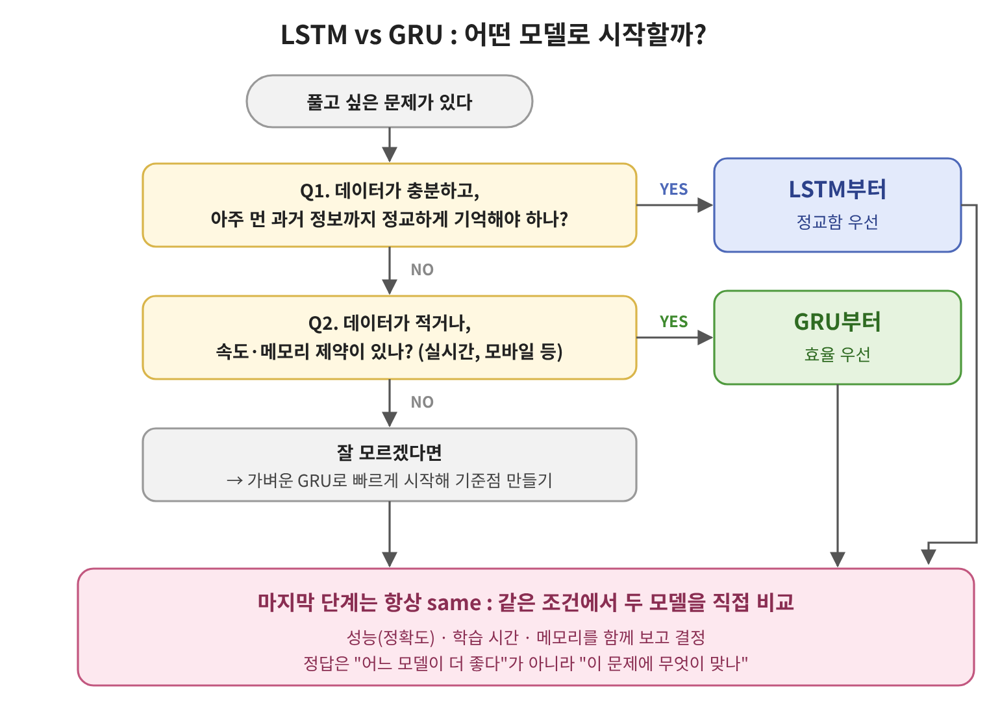 <br>
- **문제 상황에 따라 적합한 모델이 다르다.**



# 5. Seq2Seq 문장을 입력받아 문장을 출력
## 5-(1) 기본 구조 = 인코더 + 디코더
- 정의 : 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
- 입력과 출력의 길이가 달라도 된다는 점이 RNN와의 가장 큰 차이이다. <br>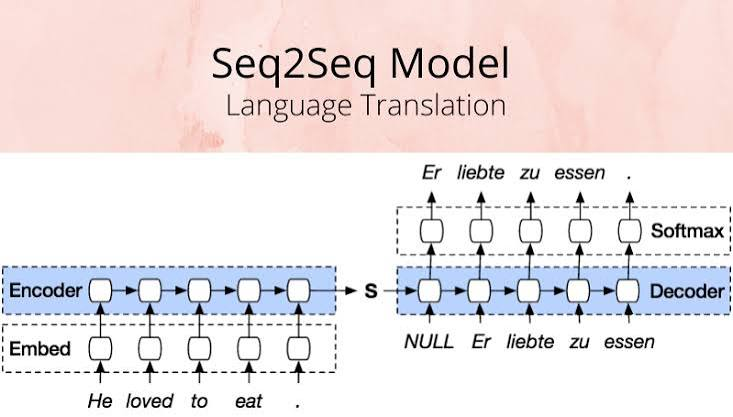 <br>
- many to many 를 두 개의 LSTM으로 나눠서 구현한 구조이다.
- 활용 : 기계 번역, 챗봇의 질문과 답변, 문서 요약 등

- 특징
     * 인코더와 디코더 두 개의 모듈로 구성
     * 인코더 (읽고) : 입력 문장을 읽고 하나의 컨텍스트 벡터로 압축
     * 컨텍스트 벡터 (요약해서 넘기고) : 인코더와 디코더의 연결고리 & 인코더를 거치며 합축된 정보
     * 디코더 (다시 써낸다 ): 컨텍스트 벡터를 받아서 출력 문장을 하나씩 생성
     * 내부 셀 = 주로 LSTM , GRU (장기의존성문제때문에)

### 1. 인코더
- 입력 문장의 모든 단어를 순서대로 읽고 컨텍스트 벡터로 압축하는 LSTM
- 작동원리
     * 1. 단어 토큰화 : 입력 문장 -> 단어 단위
     * 2. 임베딩 : 각 단어를 컴퓨터가 계산할 수 있는 숫자 벡터로 변환
     * 3. LSTM 셀에 한 단어씩 입력 : 매 시점 은닉 상태가 다음 시점으로 전달 -> 정보 누적
     * 4. 마지막 시점의 은닉 상태 = 문장 전체 정보가 담긴 *컨텍스트 벡터* -> 디코더로... (마지막 은닉 상태인 컨텍스트 벡터만 디코더로)

    ### 2. 디코더
    - 컨텍스트 벡터 -> 출력 문장을 한 단어씩 생성 LSTM
    - 작동 원리
         * 1. 컨텍스트 벡터를 첫 은닉 상태로 받음
         * 2. 시작 신호를 첫 입력으로 넣음 <sos>
         * 3. 매 시점 softmax 로 다음 단어의 확률을 계산 -> 가장 확률이 높은 단어를 선택 (argmax)
         * 4. 방금 예측한 단어 -> 다음 시점의 입력으로 다시 넣음
         * 5. 종료 신호 <eos> -> 종료

    ### 3. 컨텍스트 벡터
    - 인코더가 입력 문장 전체를 읽고 만든 *문장 요약 벡터*
    - 인코더 LSTM의 마지막 시점 은닉 상태
    - 인코더와 디코더를 연결하는 유일한 통로
    - 차원 설정
         * 컨텍스트 벡터 크기 = 인코더 LSTM 의 은닉 상태 크기 -> 사람이 정하는 *하이퍼파라미터*
         * 실제로는 수백차원
         * 디코더 LSTM의 은닉 상태 크기도 같은 값으로 맞춰둬야 이어받을 수 있다.
         * 차원이 크면 -> 많은 정보 but 계산량 늘고, 과적합 위험
         * 차원이 작으면 -> 빠르나 긴 문장의 정보를 다 담지 못함

## 5-(2) 한계 : 병목 현상
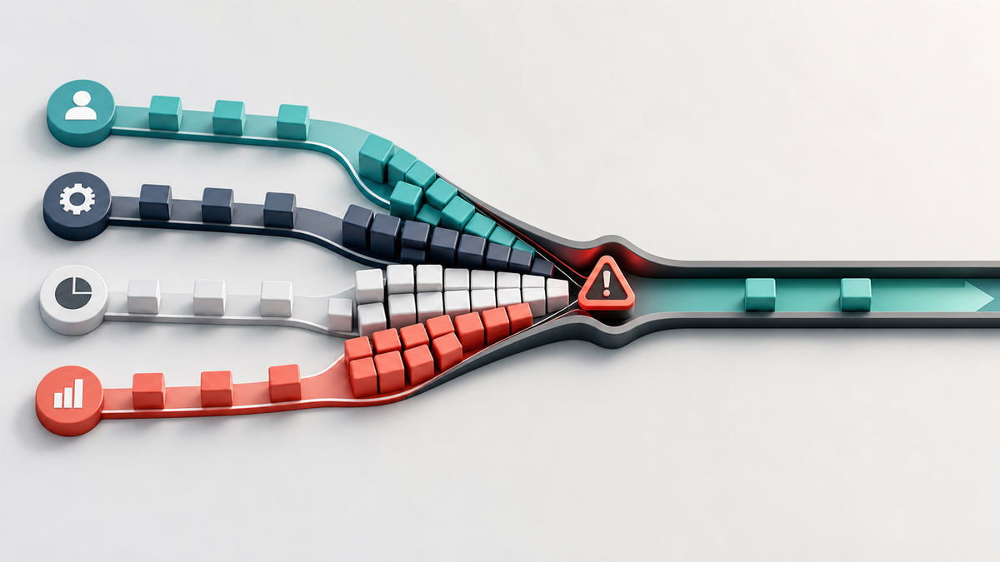 <br>
- 정의 : 인코더가 입력 문장 전체를 *고정된 크기의 컨텍스트 벡터 하나*에 압축하면서 정보가 좁은 통로에 막혀 손실되는 현상
- 어떤 단어이든 같은 크기에 담아야 함 -> 긴 문장일수록 손실이 크다
- 앞 단어는 여러 시점을 거치면서 희미해진다 -> 장기 의존성 문제 = 입력 문장이 길어질수록 기본 seq2seq의 번역 품질이 급격히 떨어진다.
- Attention이 이러한 한계를 해결해줌